## 1. Setup and Dependencies

In [1]:
# Install required packages
!pip install -q kaggle tensorflow matplotlib seaborn scikit-learn

In [2]:
# Import libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# TensorFlow imports
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# Sklearn imports
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_curve, auc,
    precision_recall_curve, accuracy_score, precision_score,
    recall_score, f1_score
)

print(f"TensorFlow Version: {tf.__version__}")
print(f"GPU Available: {tf.config.list_physical_devices('GPU')}")

TensorFlow Version: 2.19.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Setup Kaggle API and Download Dataset

In [3]:
# Create Kaggle directory and upload your kaggle.json file
# You need to upload your kaggle.json file from Kaggle account settings

from google.colab import files

# Create .kaggle directory
!mkdir -p ~/.kaggle

# Upload kaggle.json
print("Please upload your kaggle.json file:")
uploaded = files.upload()

# Move to correct location
!mv kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

print("\n✅ Kaggle API configured successfully!")

Please upload your kaggle.json file:


Saving kaggle.json to kaggle.json

✅ Kaggle API configured successfully!


In [4]:
# Download the Chest X-Ray Pneumonia dataset
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia

# Unzip the dataset
!unzip -q chest-xray-pneumonia.zip -d ./data

print("\n✅ Dataset downloaded and extracted!")

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
 95% 2.19G/2.29G [00:19<00:03, 33.2MB/s]
100% 2.29G/2.29G [00:20<00:00, 123MB/s] 

✅ Dataset downloaded and extracted!


In [5]:
# Define data paths
DATA_DIR = Path('./data/chest_xray')
TRAIN_DIR = DATA_DIR / 'train'
VAL_DIR = DATA_DIR / 'val'
TEST_DIR = DATA_DIR / 'test'

# Check directory structure
print("📁 Dataset Structure:")
for split in ['train', 'val', 'test']:
    split_dir = DATA_DIR / split
    if split_dir.exists():
        for cls in ['NORMAL', 'PNEUMONIA']:
            cls_dir = split_dir / cls
            if cls_dir.exists():
                count = len(list(cls_dir.glob('*')))
                print(f"  {split}/{cls}: {count} images")

📁 Dataset Structure:
  train/NORMAL: 1341 images
  train/PNEUMONIA: 3875 images
  val/NORMAL: 8 images
  val/PNEUMONIA: 8 images
  test/NORMAL: 234 images
  test/PNEUMONIA: 390 images


## 3. Data Exploration and Visualization

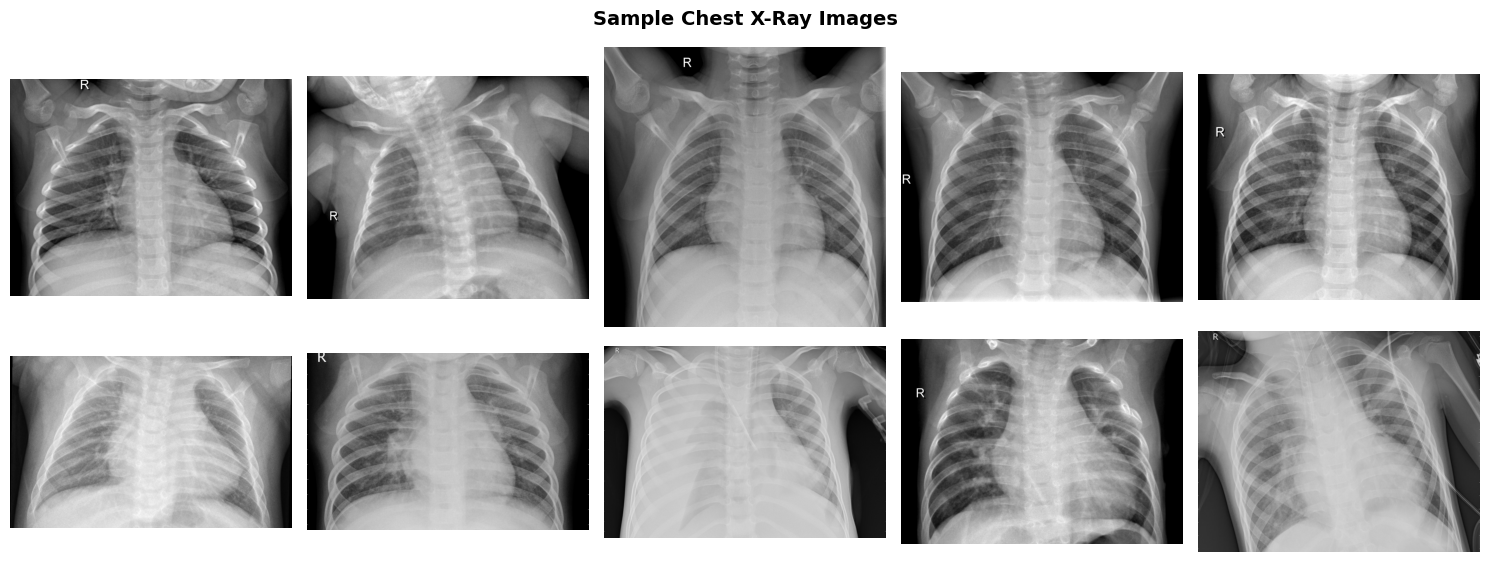

In [6]:
# Visualize sample images
def plot_sample_images(data_dir, n_samples=5):
    """Plot sample images from each class"""
    fig, axes = plt.subplots(2, n_samples, figsize=(15, 6))

    for i, cls in enumerate(['NORMAL', 'PNEUMONIA']):
        cls_dir = data_dir / 'train' / cls
        images = list(cls_dir.glob('*'))[:n_samples]

        for j, img_path in enumerate(images):
            img = plt.imread(str(img_path))
            axes[i, j].imshow(img, cmap='gray')
            axes[i, j].axis('off')
            if j == 0:
                axes[i, j].set_ylabel(cls, fontsize=12)

    plt.suptitle('Sample Chest X-Ray Images', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

plot_sample_images(DATA_DIR)

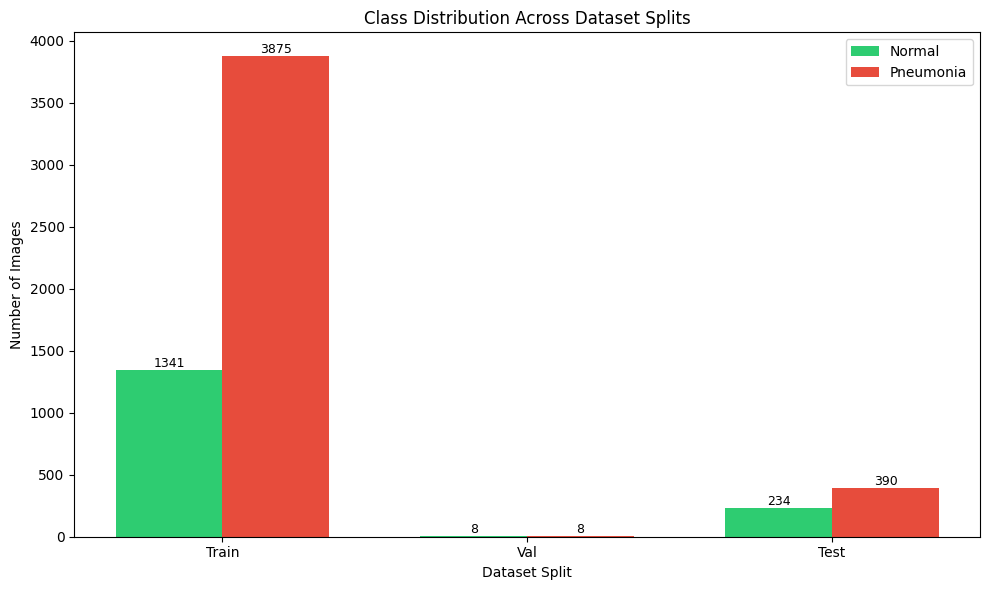

In [7]:
# Plot class distribution
def plot_class_distribution(data_dir):
    """Plot class distribution across splits"""
    splits = ['train', 'val', 'test']
    classes = ['NORMAL', 'PNEUMONIA']

    data = []
    for split in splits:
        for cls in classes:
            cls_dir = data_dir / split / cls
            if cls_dir.exists():
                count = len(list(cls_dir.glob('*')))
                data.append({'Split': split.title(), 'Class': cls, 'Count': count})

    df = pd.DataFrame(data)

    fig, ax = plt.subplots(figsize=(10, 6))
    x = np.arange(len(splits))
    width = 0.35

    normal_counts = df[df['Class'] == 'NORMAL']['Count'].values
    pneumonia_counts = df[df['Class'] == 'PNEUMONIA']['Count'].values

    bars1 = ax.bar(x - width/2, normal_counts, width, label='Normal', color='#2ecc71')
    bars2 = ax.bar(x + width/2, pneumonia_counts, width, label='Pneumonia', color='#e74c3c')

    ax.set_xlabel('Dataset Split')
    ax.set_ylabel('Number of Images')
    ax.set_title('Class Distribution Across Dataset Splits')
    ax.set_xticks(x)
    ax.set_xticklabels([s.title() for s in splits])
    ax.legend()

    # Add value labels
    for bars in [bars1, bars2]:
        for bar in bars:
            height = bar.get_height()
            ax.annotate(f'{int(height)}',
                       xy=(bar.get_x() + bar.get_width() / 2, height),
                       ha='center', va='bottom', fontsize=9)

    plt.tight_layout()
    plt.show()

plot_class_distribution(DATA_DIR)

## 4. Data Preprocessing and Augmentation

In [8]:
# Configuration
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 30
LEARNING_RATE = 0.0001

# Data augmentation for training
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Only rescaling for validation and test
val_test_datagen = ImageDataGenerator(rescale=1./255)

# Create data generators
train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=True
)

val_generator = val_test_datagen.flow_from_directory(
    VAL_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

test_generator = val_test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

print(f"\n✅ Data generators created!")
print(f"Training samples: {train_generator.samples}")
print(f"Validation samples: {val_generator.samples}")
print(f"Test samples: {test_generator.samples}")
print(f"Class indices: {train_generator.class_indices}")

Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Found 624 images belonging to 2 classes.

✅ Data generators created!
Training samples: 5216
Validation samples: 16
Test samples: 624
Class indices: {'NORMAL': 0, 'PNEUMONIA': 1}


## 5. Model Architecture - Transfer Learning with VGG16

In [9]:
def build_model(input_shape=(224, 224, 3)):
    """Build pneumonia detection model using VGG16 transfer learning"""

    # Load pre-trained VGG16 model
    base_model = VGG16(
        weights='imagenet',
        include_top=False,
        input_shape=input_shape
    )

    # Freeze base model layers
    for layer in base_model.layers:
        layer.trainable = False

    # Build custom top layers
    model = models.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dense(512, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(256, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(1, activation='sigmoid')
    ])

    return model

# Build and compile model
model = build_model()

model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc'),
             tf.keras.metrics.Precision(name='precision'),
             tf.keras.metrics.Recall(name='recall')]
)

model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,112,001 (57.65 MB)

 Trainable params: 395,777 (1.51 MB)

 Non-trainable params: 14,716,224 (56.14 MB)

## 6. Model Training

In [10]:
# Define callbacks
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),
    ModelCheckpoint(
        'pneumonia_model_best.keras',
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    )
]

# Calculate class weights for imbalanced data
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_generator.classes),
    y=train_generator.classes
)
class_weight_dict = dict(enumerate(class_weights))
print(f"Class weights: {class_weight_dict}")

Class weights: {0: np.float64(1.9448173005219984), 1: np.float64(0.6730322580645162)}


In [11]:
# Train the model
print("\n🚀 Starting training...\n")

history = model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // BATCH_SIZE,
    epochs=EPOCHS,
    validation_data=val_generator,
    validation_steps=val_generator.samples // BATCH_SIZE,
    callbacks=callbacks,
    class_weight=class_weight_dict,
    verbose=1
)

print("\n✅ Training completed!")


🚀 Starting training...

Epoch 1/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 626ms/step - accuracy: 0.7120 - auc: 0.8563 - loss: 0.5141 - precision: 0.9398 - recall: 0.6563
Epoch 1: val_accuracy improved from -inf to 0.68750, saving model to pneumonia_model_best.keras
163/163 ━━━━━━━━━━━━━━━━━━━━ 131s 680ms/step - accuracy: 0.7124 - auc: 0.8567 - loss: 0.5135 - precision: 0.9399 - recall: 0.6567 - val_accuracy: 0.6875 - val_auc: 0.7969 - val_loss: 0.6104 - val_precision: 0.6364 - val_recall: 0.8750 - learning_rate: 1.0000e-04
Epoch 2/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 615ms/step - accuracy: 0.8446 - auc: 0.9472 - loss: 0.3326 - precision: 0.9744 - recall: 0.8136
Epoch 2: val_accuracy improved from 0.68750 to 0.81250, saving model to pneumonia_model_best.keras
163/163 ━━━━━━━━━━━━━━━━━━━━ 101s 618ms/step - accuracy: 0.8446 - auc: 0.9473 - loss: 0.3325 - precision: 0.9745 - recall: 0.8137 - val_accuracy: 0.8125 - val_auc: 0.9375 - val_loss: 0.4989 - val_precision: 0.8571 - val_recall: 0.7500 - le

## 7. Training History Visualization

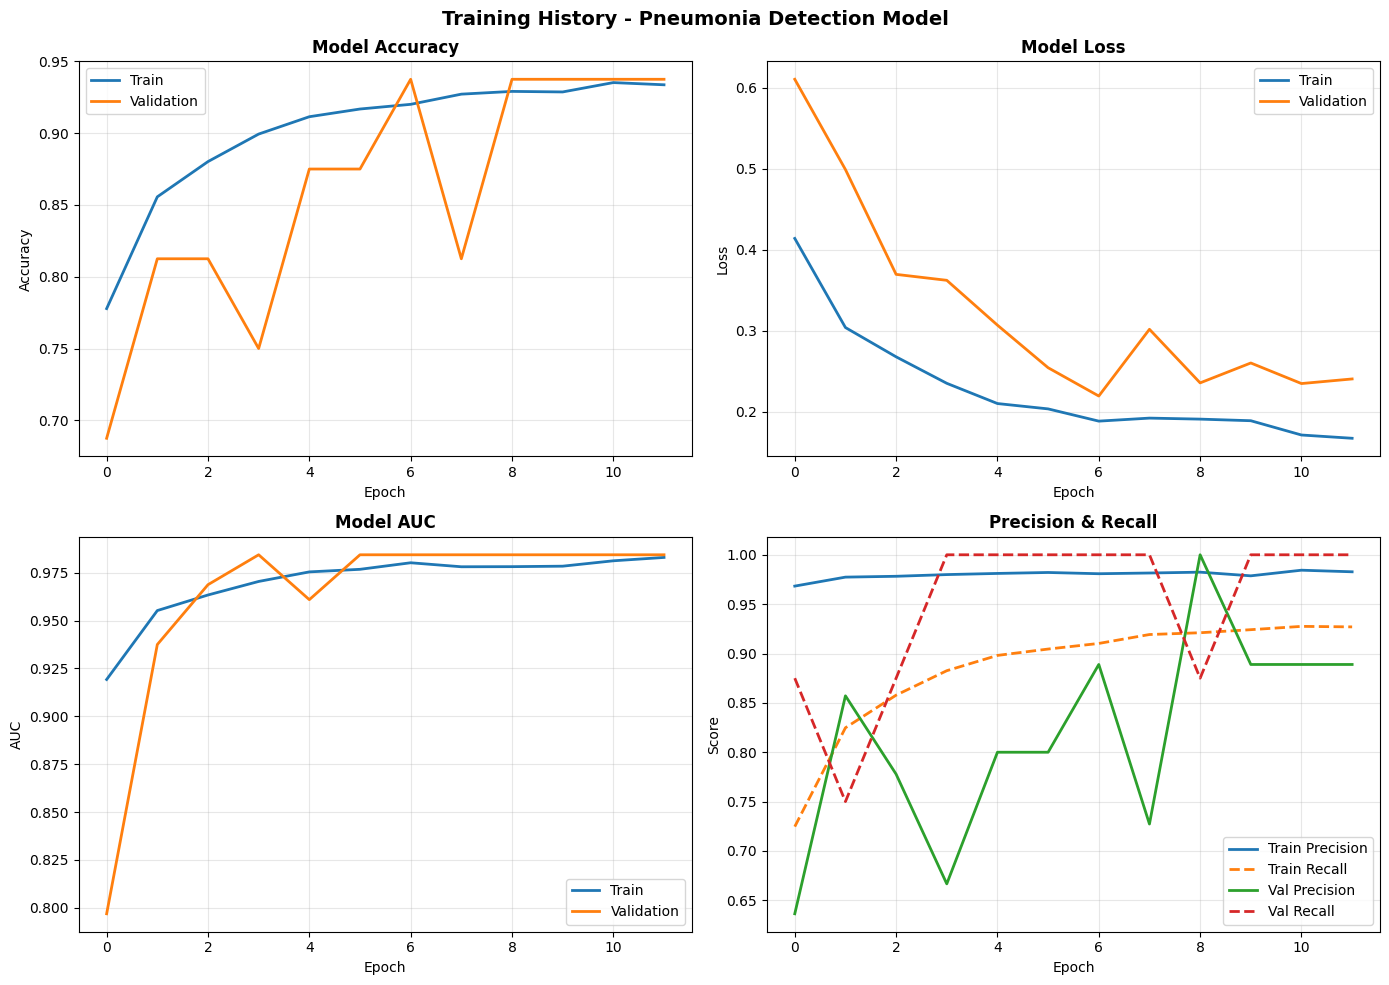

In [12]:
def plot_training_history(history):
    """Plot training and validation metrics"""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # Accuracy
    axes[0, 0].plot(history.history['accuracy'], label='Train', linewidth=2)
    axes[0, 0].plot(history.history['val_accuracy'], label='Validation', linewidth=2)
    axes[0, 0].set_title('Model Accuracy', fontsize=12, fontweight='bold')
    axes[0, 0].set_xlabel('Epoch')
    axes[0, 0].set_ylabel('Accuracy')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)

    # Loss
    axes[0, 1].plot(history.history['loss'], label='Train', linewidth=2)
    axes[0, 1].plot(history.history['val_loss'], label='Validation', linewidth=2)
    axes[0, 1].set_title('Model Loss', fontsize=12, fontweight='bold')
    axes[0, 1].set_xlabel('Epoch')
    axes[0, 1].set_ylabel('Loss')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)

    # AUC
    axes[1, 0].plot(history.history['auc'], label='Train', linewidth=2)
    axes[1, 0].plot(history.history['val_auc'], label='Validation', linewidth=2)
    axes[1, 0].set_title('Model AUC', fontsize=12, fontweight='bold')
    axes[1, 0].set_xlabel('Epoch')
    axes[1, 0].set_ylabel('AUC')
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)

    # Precision & Recall
    axes[1, 1].plot(history.history['precision'], label='Train Precision', linewidth=2)
    axes[1, 1].plot(history.history['recall'], label='Train Recall', linewidth=2, linestyle='--')
    axes[1, 1].plot(history.history['val_precision'], label='Val Precision', linewidth=2)
    axes[1, 1].plot(history.history['val_recall'], label='Val Recall', linewidth=2, linestyle='--')
    axes[1, 1].set_title('Precision & Recall', fontsize=12, fontweight='bold')
    axes[1, 1].set_xlabel('Epoch')
    axes[1, 1].set_ylabel('Score')
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3)

    plt.suptitle('Training History - Pneumonia Detection Model', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('pneumonia_training_history.png', dpi=300, bbox_inches='tight')
    plt.show()

plot_training_history(history)

## 8. Model Evaluation

In [13]:
# Load best model
model = keras.models.load_model('pneumonia_model_best.keras')

# Evaluate on test set
print("\n📊 Evaluating model on test set...\n")
test_generator.reset()
test_results = model.evaluate(test_generator, verbose=1)

print("\n" + "="*50)
print("TEST SET RESULTS")
print("="*50)
for name, value in zip(model.metrics_names, test_results):
    print(f"{name.title()}: {value:.4f}")


📊 Evaluating model on test set...

20/20 ━━━━━━━━━━━━━━━━━━━━ 8s 297ms/step - accuracy: 0.9069 - auc: 0.6341 - loss: 0.2455 - precision: 0.5636 - recall: 0.5931

TEST SET RESULTS
Loss: 0.3147
Compile_Metrics: 0.8862


In [14]:
# Get predictions
test_generator.reset()
y_pred_prob = model.predict(test_generator, verbose=1)
y_pred = (y_pred_prob > 0.5).astype(int).flatten()
y_true = test_generator.classes

# Classification Report
print("\n" + "="*50)
print("CLASSIFICATION REPORT")
print("="*50)
print(classification_report(y_true, y_pred, target_names=['Normal', 'Pneumonia']))

20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 305ms/step

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal       0.81      0.90      0.86       234
   Pneumonia       0.94      0.88      0.91       390

    accuracy                           0.89       624
   macro avg       0.88      0.89      0.88       624
weighted avg       0.89      0.89      0.89       624



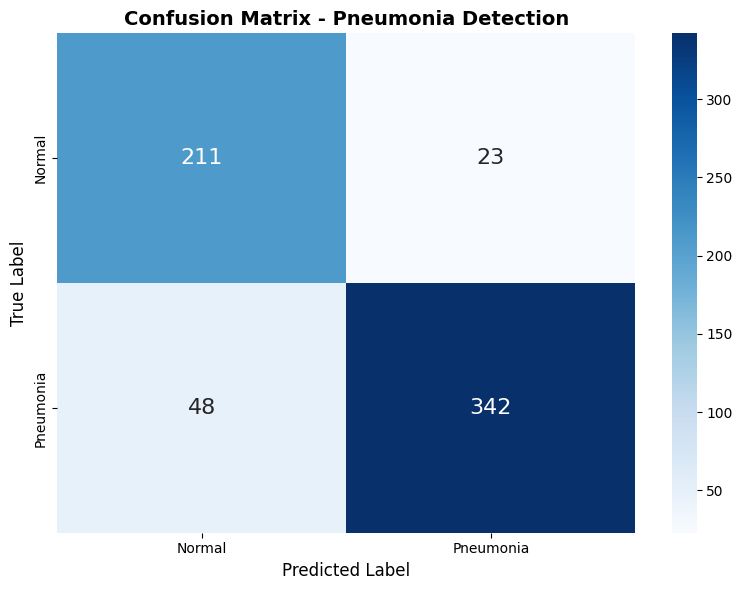


True Negatives: 211
False Positives: 23
False Negatives: 48
True Positives: 342

Sensitivity (Recall): 0.8769
Specificity: 0.9017


In [15]:
# Confusion Matrix
def plot_confusion_matrix(y_true, y_pred, classes=['Normal', 'Pneumonia']):
    """Plot confusion matrix"""
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=classes, yticklabels=classes,
                annot_kws={'size': 16})
    plt.title('Confusion Matrix - Pneumonia Detection', fontsize=14, fontweight='bold')
    plt.xlabel('Predicted Label', fontsize=12)
    plt.ylabel('True Label', fontsize=12)
    plt.tight_layout()
    plt.savefig('pneumonia_confusion_matrix.png', dpi=300, bbox_inches='tight')
    plt.show()

    # Print metrics
    tn, fp, fn, tp = cm.ravel()
    print(f"\nTrue Negatives: {tn}")
    print(f"False Positives: {fp}")
    print(f"False Negatives: {fn}")
    print(f"True Positives: {tp}")
    print(f"\nSensitivity (Recall): {tp/(tp+fn):.4f}")
    print(f"Specificity: {tn/(tn+fp):.4f}")

plot_confusion_matrix(y_true, y_pred)

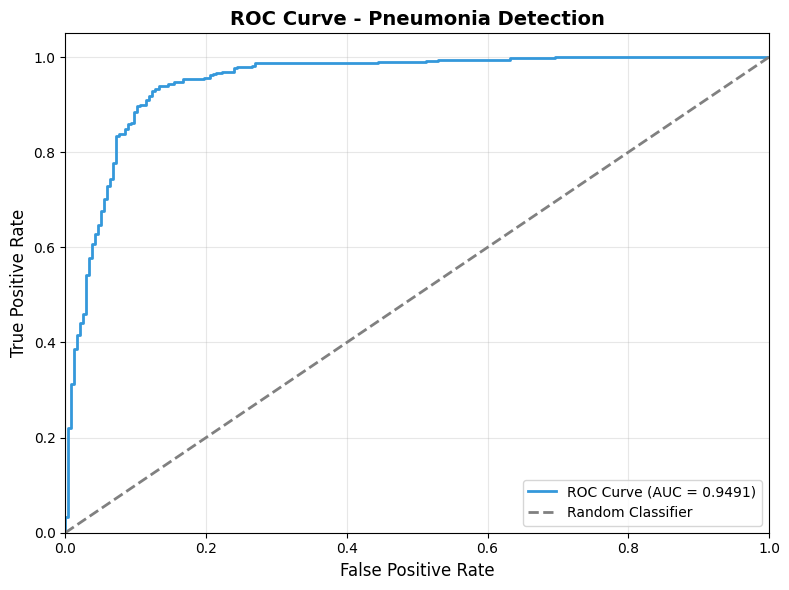

In [16]:
# ROC Curve
def plot_roc_curve(y_true, y_pred_prob):
    """Plot ROC curve"""
    fpr, tpr, thresholds = roc_curve(y_true, y_pred_prob)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='#3498db', lw=2,
             label=f'ROC Curve (AUC = {roc_auc:.4f})')
    plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--',
             label='Random Classifier')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate', fontsize=12)
    plt.ylabel('True Positive Rate', fontsize=12)
    plt.title('ROC Curve - Pneumonia Detection', fontsize=14, fontweight='bold')
    plt.legend(loc='lower right')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig('pneumonia_roc_curve.png', dpi=300, bbox_inches='tight')
    plt.show()

plot_roc_curve(y_true, y_pred_prob)

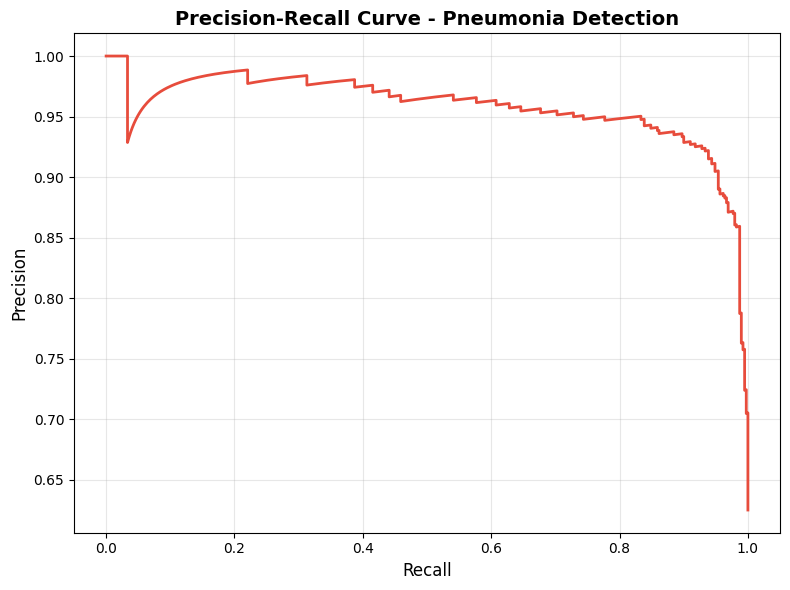

In [17]:
# Precision-Recall Curve
def plot_precision_recall_curve(y_true, y_pred_prob):
    """Plot precision-recall curve"""
    precision, recall, thresholds = precision_recall_curve(y_true, y_pred_prob)

    plt.figure(figsize=(8, 6))
    plt.plot(recall, precision, color='#e74c3c', lw=2)
    plt.xlabel('Recall', fontsize=12)
    plt.ylabel('Precision', fontsize=12)
    plt.title('Precision-Recall Curve - Pneumonia Detection', fontsize=14, fontweight='bold')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig('pneumonia_pr_curve.png', dpi=300, bbox_inches='tight')
    plt.show()

plot_precision_recall_curve(y_true, y_pred_prob)

In [18]:
# Comprehensive Metrics Summary
def print_metrics_summary(y_true, y_pred, y_pred_prob):
    """Print comprehensive metrics summary"""
    print("\n" + "="*60)
    print("COMPREHENSIVE METRICS SUMMARY - PNEUMONIA DETECTION")
    print("="*60)

    # Calculate all metrics
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    fpr, tpr, _ = roc_curve(y_true, y_pred_prob)
    roc_auc = auc(fpr, tpr)

    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    specificity = tn / (tn + fp)

    metrics = {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall (Sensitivity)': recall,
        'Specificity': specificity,
        'F1-Score': f1,
        'ROC-AUC': roc_auc
    }

    for name, value in metrics.items():
        print(f"{name:25s}: {value:.4f} ({value*100:.2f}%)")

    print("\n" + "-"*60)
    print("Confusion Matrix Values:")
    print(f"  True Positives (TP):  {tp:5d}")
    print(f"  True Negatives (TN):  {tn:5d}")
    print(f"  False Positives (FP): {fp:5d}")
    print(f"  False Negatives (FN): {fn:5d}")
    print("="*60)

print_metrics_summary(y_true, y_pred, y_pred_prob)


COMPREHENSIVE METRICS SUMMARY - PNEUMONIA DETECTION
Accuracy                 : 0.8862 (88.62%)
Precision                : 0.9370 (93.70%)
Recall (Sensitivity)     : 0.8769 (87.69%)
Specificity              : 0.9017 (90.17%)
F1-Score                 : 0.9060 (90.60%)
ROC-AUC                  : 0.9491 (94.91%)

------------------------------------------------------------
Confusion Matrix Values:
  True Positives (TP):    342
  True Negatives (TN):    211
  False Positives (FP):    23
  False Negatives (FN):    48


## 9. Save Model

In [19]:
# Save final model
model.save('pneumonia_model.keras')
print("✅ Model saved as 'pneumonia_model.keras'")

# Download model
from google.colab import files
files.download('pneumonia_model.keras')

# Also download evaluation plots
files.download('pneumonia_training_history.png')
files.download('pneumonia_confusion_matrix.png')
files.download('pneumonia_roc_curve.png')
files.download('pneumonia_pr_curve.png')

✅ Model saved as 'pneumonia_model.keras'


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Sample Predictions Visualization

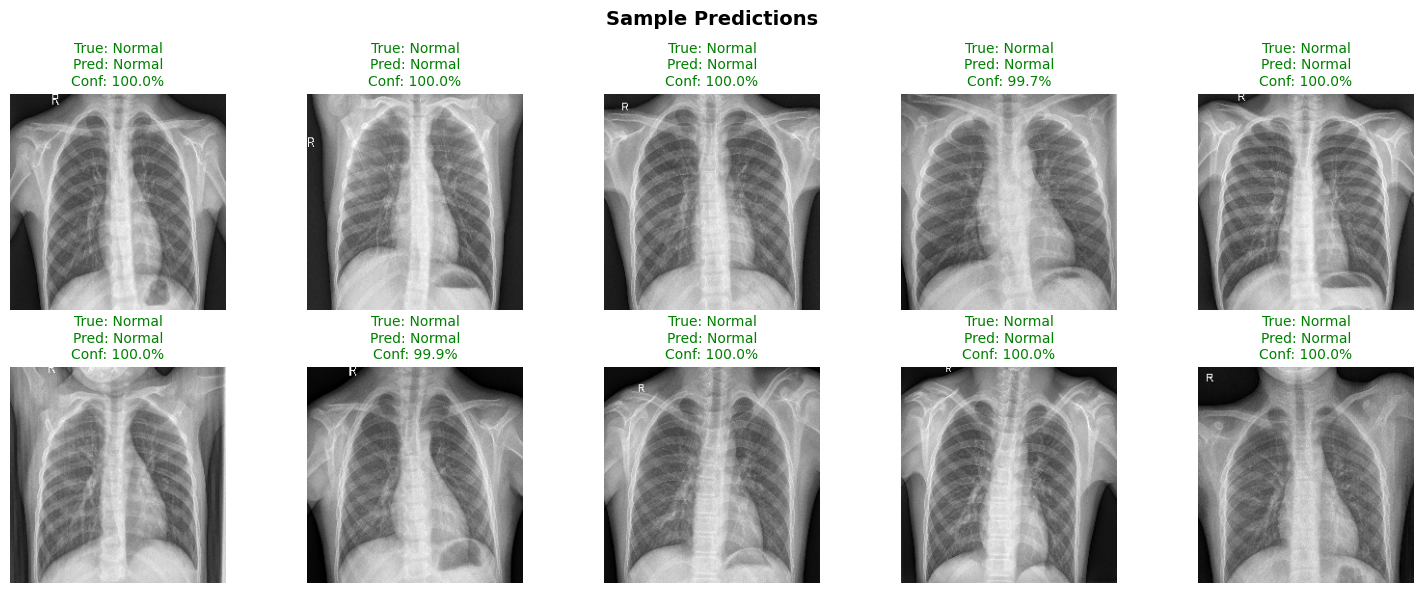

In [20]:
def visualize_predictions(model, test_generator, n_samples=10):
    """Visualize sample predictions"""
    test_generator.reset()
    batch = next(test_generator)
    images, labels = batch

    predictions = model.predict(images[:n_samples], verbose=0)

    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    axes = axes.flatten()

    class_names = ['Normal', 'Pneumonia']

    for i in range(n_samples):
        ax = axes[i]
        ax.imshow(images[i])

        pred_class = int(predictions[i] > 0.5)
        true_class = int(labels[i])
        confidence = predictions[i][0] if pred_class == 1 else 1 - predictions[i][0]

        color = 'green' if pred_class == true_class else 'red'

        ax.set_title(f'True: {class_names[true_class]}\n'
                    f'Pred: {class_names[pred_class]}\n'
                    f'Conf: {confidence*100:.1f}%',
                    color=color, fontsize=10)
        ax.axis('off')

    plt.suptitle('Sample Predictions', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('pneumonia_sample_predictions.png', dpi=300, bbox_inches='tight')
    plt.show()

visualize_predictions(model, test_generator)

## Summary

This notebook trained a pneumonia detection model using:
- **Dataset**: Kaggle Chest X-Ray Pneumonia dataset
- **Architecture**: VGG16 with transfer learning
- **Input**: 224x224 RGB images
- **Output**: Binary classification (Normal/Pneumonia)

The model has been saved as `pneumonia_model.keras` and can be deployed in the HealthMate ML service.